# Exercises XP — Titanic preprocessing

Octopus Week 2 · Day 2

[Assignment](https://octopus.developers.institute/courses/collection/254/course/812/section/1694/chapter/3305)

Run cells in order. Source datasets are in `../data`; see the root README for setup and provenance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis_utils.py').exists())
sys.path.insert(0, str(ROOT))
sns.set_theme(style='whitegrid')
def load(kind, filename=None, **kwargs):
    files = list((ROOT / 'data' / kind).rglob(filename or '*.csv'))
    if len(files) != 1:
        raise ValueError(f'Select an unambiguous data file: {files}')
    return pd.read_csv(files[0], **kwargs)
def savefig(name):
    target = ROOT / 'figures'
    target.mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(target / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()


## Exercise 1 — Duplicate detection
Follow a single preprocessing narrative. Keep raw data intact. Identity, target and free-text columns are excluded from the final feature matrix. These are descriptive exercises: a predictive workflow must split first and fit imputation/scaling only on its training fold.

In [2]:
raw=load('titanic')
print('Before:',len(raw),'duplicates:',raw.duplicated().sum())
df=raw.drop_duplicates().copy()
print('After:',len(df))
assert not df.duplicated().any()

Before: 891 duplicates: 0
After: 891


## Exercise 2 — Missing values
Age: median imputation is robust to skew. Embarked: fill with its modal category. Cabin: retain an explicit Unknown category rather than invent a cabin. Removal is demonstrated on a separate complete-case copy; it is not used for the main analysis because it discards many passengers.

In [3]:
display(df.isna().sum().to_frame('missing_before'))
complete_case=df.dropna()
print('Complete-case alternative:',len(complete_case),'rows; main pipeline retains',len(df))
df['Age']=df['Age'].fillna(df['Age'].median())
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode().iloc[0])
df['Cabin']=df['Cabin'].fillna('Unknown')
display(df.isna().sum().to_frame('missing_after'))

,missing_before
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Complete-case alternative: 183 rows; main pipeline retains 891


,missing_after
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## Exercise 3 — Feature engineering
FamilySize includes the passenger. Title is extracted from Name. Its one-hot encoding is previewed now and merged with other nominal features only after missing values and outliers have been addressed, reconciling the assignment's ordering reminders.

In [4]:
df['FamilySize']=df['SibSp']+df['Parch']+1
df['Title']=df['Name'].str.extract(r',\s*([^\.]+)\.',expand=False)
display(df[['Name','Title','FamilySize']].head())
display(pd.get_dummies(df['Title'],prefix='Title',dtype=int).head())

,Name,Title,FamilySize
0,"Braund, Mr. Owen Harris",Mr,2
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2
2,"Heikkinen, Miss. Laina",Miss,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2
4,"Allen, Mr. William Henry",Mr,1


,Title_Capt,Title_Col,Title_Don,Title_Dr,Title_Jonkheer,Title_Lady,Title_Major,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


## Exercise 4 — Outliers
Use IQR flags diagnostically. Rare large fares may be real, so retain rows and cap Fare at empirical 2nd/98th percentiles for the scaling demonstration. Age is also capped for the demonstration, while original Age remains available for interpretation. Log1p(Fare) is an alternative. Neither an older passenger nor a costly ticket is automatically an error.

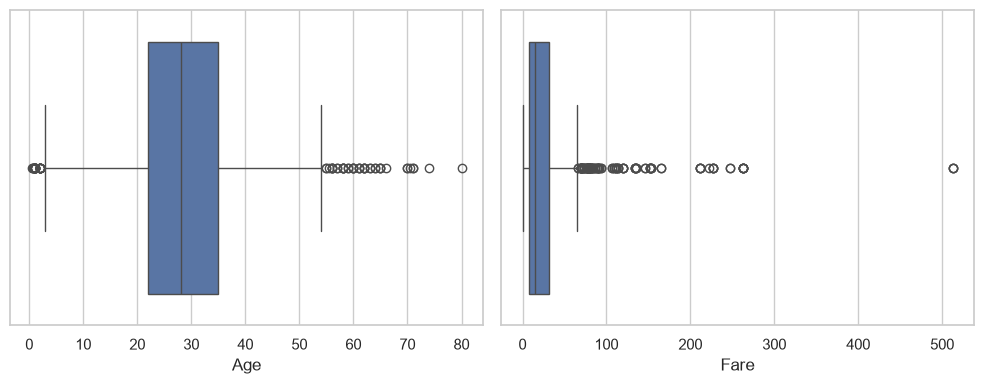

Age IQR flags: 66 caps: 2.0 62.0 alternative rows after removal: 825
Fare IQR flags: 116 caps: 6.3975 211.3375 alternative rows after removal: 775


,Age,Age_capped,Fare,Fare_capped,Fare_log
count,891.000000,891.000000,891.000000,891.00000,891.000000
mean,29.361582,29.276655,32.204208,30.79061,2.991460
std,13.019697,12.681007,49.693429,39.82766,0.881183
min,0.420000,2.000000,0.000000,6.39750,2.001142
25%,22.000000,22.000000,7.910400,7.91040,2.187218
50%,28.000000,28.000000,14.454200,14.45420,2.737881
75%,35.000000,35.000000,31.000000,31.00000,3.465736
max,80.000000,62.000000,512.329200,211.33750,5.358177


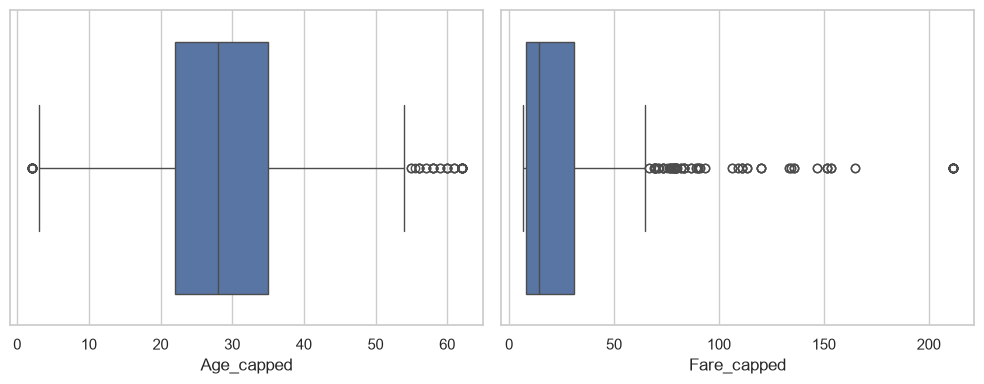

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,col in zip(axes,['Age','Fare']):
    sns.boxplot(x=df[col],ax=ax)
savefig('day2_before_outliers')
for col in ['Age','Fare']:
    q1,q3=df[col].quantile([.25,.75]); iqr=q3-q1
    flag=(df[col]<q1-1.5*iqr)|(df[col]>q3+1.5*iqr)
    low,high=df[col].quantile([.02,.98])
    print(col,'IQR flags:',int(flag.sum()),'caps:',low,high,'alternative rows after removal:',int((~flag).sum()))
    df[col+'_capped']=df[col].clip(low,high)
df['Fare_log']=np.log1p(df['Fare_capped'])
display(df[['Age','Age_capped','Fare','Fare_capped','Fare_log']].describe())
fig,axes=plt.subplots(1,2,figsize=(10,4))
sns.boxplot(x=df['Age_capped'],ax=axes[0]); sns.boxplot(x=df['Fare_capped'],ax=axes[1])
savefig('day2_after_outliers')

## Exercise 5 — Standardization and normalization
Standardize capped Age to demonstrate z scores; Age is not assumed to be exactly normal. Min-max scale capped Fare to [0,1]. Scaling changes units, not distribution shape. The encoding and age groups below are computed before the final matrix is assembled.

In [6]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler
df['Age_z']=StandardScaler().fit_transform(df[['Age_capped']]).ravel()
df['Fare_01']=MinMaxScaler().fit_transform(df[['Fare_capped']]).ravel()
display(df[['Age_z','Fare_01']].describe())

,Age_z,Fare_01
count,8.910000e+02,891.000000
mean,3.987333e-17,0.119026
std,1.000562e+00,0.194338
min,-2.152193e+00,0.000000
25%,-5.741455e-01,0.007382
50%,-1.007312e-01,0.039312
75%,4.515855e-01,0.120047
max,2.581950e+00,1.000000


## Exercise 6 — Nominal encoding
Sex, Embarked and Title have no defensible ordinal rank. Use one-hot encoding; do not label-encode arbitrary categories as ordered numbers. Pclass is an existing ordinal class code.

In [7]:
encoded=pd.get_dummies(df,columns=['Sex','Embarked','Title'],dtype=int)
display(encoded.filter(regex='^(Sex|Embarked|Title)_').head())

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Capt,Title_Col,Title_Don,Title_Dr,Title_Jonkheer,...,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,1,0,0,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


## Exercise 7 — Age groups
Use original, imputed Age for interpretable boundaries: child ≤12, teen (12,18], adult (18,60], senior >60. Include age zero for infants. One-hot encode the groups; keep the original age for audit.

In [8]:
df['AgeGroup']=pd.cut(df['Age'],bins=[0,12,18,60,120],labels=['child','teen','adult','senior'],include_lowest=True)
display(df['AgeGroup'].value_counts(sort=False))
display(pd.get_dummies(df['AgeGroup'],prefix='AgeGroup',dtype=int).head())
from analysis_utils import prepare_titanic
processed,audit=prepare_titanic(raw)
display(pd.Series(audit))
features=processed.drop(columns=['PassengerId','Survived','Age','Fare','Age_capped','Fare_capped'])
assert not features.isna().any().any()
assert all(pd.api.types.is_numeric_dtype(t) for t in features.dtypes)
assert processed['Fare_01'].between(0,1).all()
assert np.isclose(processed['Age_z'].mean(),0)
assert np.isclose(processed['Age_z'].std(ddof=0),1)
processed.to_csv(ROOT/'day2'/'titanic_preprocessed.csv',index=False)
print('Final feature matrix:',features.shape,'; target kept separately:',raw['Survived'].name)

AgeGroup
child      69
teen       70
adult     730
senior     22
Name: count, dtype: int64

,AgeGroup_child,AgeGroup_teen,AgeGroup_adult,AgeGroup_senior
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,1,0
4,0,0,1,0


rows_before                          891
duplicates_removed                     0
Age_caps                     [2.0, 62.0]
Fare_caps             [6.3975, 211.3375]
rows_after                           891
dtype: object

Final feature matrix: (891, 33) ; target kept separately: Survived
